# R7 · Whole-tile and gene-list queries on every section (Fig 7)

On each of the 8 indexed sections and seeds 0–4:
* **Whole-tile queries:** every held-out tile is searched with Spindle-naive (top 10 by exact d_B) and Spindle (its
  first 10). The readout is the composition difference (total variation, TV) between the query and the pooled cells of
  the 10 tiles, against a random 10. The expression top 10 is recorded but never claimed.
* **Gene-list queries:** each curated tissue signature, as a template query, is searched with Spindle-naive
  (exact d_B^S) and Spindle. Controls are variances only (D) and the highest tile score (X). Readouts: Cliff's δ of the
  tile score, co-variation lift on S and Jaccard indices.
* **Skin worked example (seed 0):** the keratinocyte-rich query tile with its top 10, and the signature maps.

The rules are fixed in `experiments/common/queries.py`.

* **Prerequisites:** `R0_index_cache.ipynb`.
* **Writes:** `results/queries/`:
  * `per_dataset/<key>/seed<s>_{tile_queries,gene_lists}.csv`
  * `skin_example/` (`example.csv`, `skin_classes.csv`, `example_cells.npz`, `signature_cells.npz`)
  * `tiles.csv`, `lists.csv` (summaries over seeds)
* **Skips** every (dataset, seed) whose CSVs exist (`FORCE = True` redoes all).
* **Runtime / memory:** about 1–2 h in total on one core; peak about 6 GB (brain_cancer: 817k cells × 480 genes, counts and
  log-expression in float32).

In [1]:
import gc
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import queries as qx
import results_io as rio
import sections as sx

FORCE = False
TOPIC = "queries"
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v2-dirty', 'commit': '8040f91'}


## Queries, one (dataset, seed) at a time

In [2]:
def save_npz(arrays, file, description):
    path = rio.topic(TOPIC) / file
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, **arrays)
    rio.register(TOPIC, path, description)


for key in data.indexed_keys():
    for seed in data.SEEDS:
        d = f"per_dataset/{key}"
        example = key == qx.EXAMPLE_KEY and seed == data.EXAMPLE_SEED
        need = [rio.topic(TOPIC) / d / f"seed{seed}_{n}.csv" for n in ("tile_queries", "gene_lists")]
        if example:
            need += [rio.topic(TOPIC) / "skin_example" / f for f in ("example.csv", "signature_cells.npz")]
        if not FORCE and all(p.exists() for p in need):
            print(f"{key} seed {seed}: exists, skipped")
            continue
        S = sx.load(key, seed, parts=qx.PARTS)
        T, tops = qx.tile_queries(S, seed)
        rio.write_csv(T, TOPIC, f"{d}/seed{seed}_tile_queries.csv",
                      "every held-out tile: composition difference (TV) to Spindle-naive's top 10, Spindle's first 10, "
                      "a random 10 (mean of 200) and the expression top 10")
        print(f"{key} seed {seed}: {len(T)} of {len(S['c'].test)} queries; TV Spindle-naive {T.tv_naive.median():.3f}, "
              f"Spindle {T.tv_spindle.median():.3f}, random {T.tv_random.median():.3f}, expression "
              f"{T.tv_expr.median():.3f}; below random {(T.tv_naive < T.tv_random).mean():.3f} "
              f"(Spindle {(T.tv_spindle < T.tv_random).mean():.3f})")
        if example:
            ex, table, arrays = qx.skin_example(S, T, tops)
            rio.write_csv(ex, TOPIC, "skin_example/example.csv",
                          "skin example: class composition of the query, Spindle-naive's top 10, a random 10, the section")
            rio.write_csv(table, TOPIC, "skin_example/skin_classes.csv", "skin graph-based clusters -> skin classes")
            save_npz(arrays, "skin_example/example_cells.npz", "skin example: cells, classes, query and top-10 tiles")
        G, arrays = qx.gene_lists(S, seed, keep_cells=example)
        rio.write_csv(G, TOPIC, f"{d}/seed{seed}_gene_lists.csv",
                      "every tissue signature x method (naive_partial, spindle_partial, D, X): delta, co-variation, Jaccard")
        if example:
            save_npz(arrays, "skin_example/signature_cells.npz", "skin signatures: cell scores, Spindle-naive's 10 tiles")
        del S, T, tops, G, arrays
        gc.collect()
        print(f"  peak memory so far {rio.peak_rss_gb():.1f} GB", flush=True)

skin_melanoma seed 0: exists, skipped
skin_melanoma seed 1: exists, skipped
skin_melanoma seed 2: exists, skipped
skin_melanoma seed 3: exists, skipped
skin_melanoma seed 4: exists, skipped
kidney_nondiseased seed 0: exists, skipped
kidney_nondiseased seed 1: exists, skipped
kidney_nondiseased seed 2: exists, skipped
kidney_nondiseased seed 3: exists, skipped
kidney_nondiseased seed 4: exists, skipped
wrote results/queries/per_dataset/breast_cancer/seed0_tile_queries.csv: 204 rows
breast_cancer seed 0: 204 of 204 queries; TV Spindle-naive 0.128, Spindle 0.159, random 0.531, expression 0.108; below random 1.000 (Spindle 0.975)
wrote results/queries/per_dataset/breast_cancer/seed0_gene_lists.csv: 20 rows
  peak memory so far 1.0 GB
wrote results/queries/per_dataset/breast_cancer/seed1_tile_queries.csv: 204 rows
breast_cancer seed 1: 204 of 204 queries; TV Spindle-naive 0.130, Spindle 0.146, random 0.525, expression 0.101; below random 1.000 (Spindle 0.985)
wrote results/queries/per_datas

## Summaries over seeds

In [3]:
def read_all(name):
    return pd.concat([pd.read_csv(rio.topic(TOPIC) / f"per_dataset/{k}/seed{s}_{name}.csv")
                      for k in data.indexed_keys() for s in data.SEEDS], ignore_index=True)


tiles = qx.summary_tiles(read_all("tile_queries"))
lists = qx.summary_lists(read_all("gene_lists"))
rio.write_csv(tiles, TOPIC, "tiles.csv", "per dataset and seed: median composition differences, shares below random")
rio.write_csv(lists, TOPIC, "lists.csv", "per dataset, list and method: mean and s.d. over seeds")
tiles.groupby("key", sort=False)[["n_queries", "tv_naive", "tv_spindle", "tv_random", "tv_expr", "below_random",
                                  "spindle_below_random"]].mean().round(3)

wrote results/queries/tiles.csv: 40 rows
wrote results/queries/lists.csv: 96 rows


,n_queries,tv_naive,tv_spindle,tv_random,tv_expr,below_random,spindle_below_random
key,,,,,,,
skin_melanoma,93.0,0.217,0.224,0.581,0.205,0.998,0.996
kidney_nondiseased,78.0,0.203,0.215,0.348,0.195,0.985,0.974
breast_cancer,204.0,0.133,0.154,0.538,0.103,0.998,0.981
lung_cancer,170.0,0.210,0.209,0.466,0.195,0.972,0.979
pancreatic_cancer,229.0,0.223,0.249,0.492,0.209,0.985,0.959
lymph_node,261.0,0.193,0.204,0.419,0.188,0.996,0.991
lymph_node_5k,774.0,0.243,0.263,0.407,0.227,0.995,0.957
brain_cancer,1062.0,0.227,0.232,0.357,0.202,0.963,0.937


In [4]:
lists[lists.method.isin(["naive_partial", "spindle_partial"])].pivot_table(
    index=["key", "list"], columns="method", values=["delta", "lift"], sort=False).round(3)

delta                  \
method                                        naive_partial spindle_partial   
key                list                                                       
skin_melanoma      Melanocyte_Tumor                   0.874           0.815   
                   Keratinocyte_Epidermis             0.783           0.786   
                   Immune_Infiltrate                  0.819           0.878   
kidney_nondiseased Tubular_Epithelium                 0.675           0.653   
                   Injury_Immune_Infiltrate           0.566           0.278   
breast_cancer      Luminal_Tumor_Core                 0.729           0.642   
                   Macrophage_Myeloid                 0.546           0.741   
                   Basal_Myoepithelial                0.803           0.813   
                   Endothelial_Vascular               0.920           0.685   
                   Proliferation_Signature            0.739           0.687   
lung_cancer        Alveolar_Airway_Epithelium         0.368           0.434   
                   Vascular_Endothelial               0.821           0.706   
pancreatic_cancer  Exocrine_Ductal                    0.557           0.566   
                   Endocrine_Islet                    0.775           0.766   
                   Mast_Cell_Stroma                   0.834           0.867   
lymph_node         B_Cell_Germinal_Center             0.514           0.510   
                   T_Cell_Zone                        0.657           0.677   
                   Macrophage_DC_Niche                0.714           0.704   
                   Lymphatic_Vascular_Stroma          0.861           0.934   
lymph_node_5k      B_Cell_Germinal_Center             0.767           0.754   
                   T_Cell_Zone                        0.677           0.688   
brain_cancer       Glioma_Tumor_Proliferative         0.330           0.349   
                   Microglia_Myeloid                  0.417           0.552   
                   TIL_Lymphocyte                     0.068           0.182   

                                                       lift                  
method                                        naive_partial spindle_partial  
key                list                                                      
skin_melanoma      Melanocyte_Tumor                   0.076           0.135  
                   Keratinocyte_Epidermis             0.264           0.275  
                   Immune_Infiltrate                  0.016          -0.052  
kidney_nondiseased Tubular_Epithelium                -0.035          -0.033  
                   Injury_Immune_Infiltrate           0.024          -0.008  
breast_cancer      Luminal_Tumor_Core                 0.021           0.066  
                   Macrophage_Myeloid                 0.107           0.033  
                   Basal_Myoepithelial                0.432           0.393  
                   Endothelial_Vascular               0.079           0.168  
                   Proliferation_Signature            0.161           0.172  
lung_cancer        Alveolar_Airway_Epithelium         0.001          -0.014  
                   Vascular_Endothelial               0.298           0.166  
pancreatic_cancer  Exocrine_Ductal                    0.128           0.126  
                   Endocrine_Islet                    0.393           0.354  
                   Mast_Cell_Stroma                   0.062           0.046  
lymph_node         B_Cell_Germinal_Center             0.009           0.013  
                   T_Cell_Zone                        0.001          -0.037  
                   Macrophage_DC_Niche                0.061           0.071  
                   Lymphatic_Vascular_Stroma          0.055           0.083  
lymph_node_5k      B_Cell_Germinal_Center             0.011          -0.004  
                   T_Cell_Zone                       -0.050          -0.053  
brain_cancer       Glioma_Tumor_Proliferative   

## Quick look (not saved)

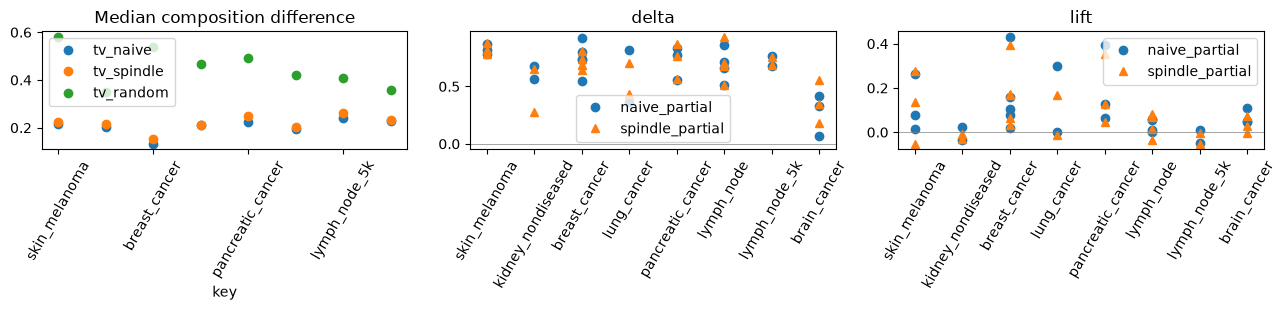

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
m = tiles.groupby("key", sort=False)[["tv_naive", "tv_spindle", "tv_random"]].mean()
m.plot(ax=ax[0], marker="o", ls="", rot=60, title="Median composition difference")
for a, col in zip(ax[1:], ("delta", "lift")):
    for meth, mk in (("naive_partial", "o"), ("spindle_partial", "^")):
        v = lists[lists.method == meth]
        a.plot(v.key, v[col], mk, ls="", label=meth)
    a.axhline(0, color="grey", lw=0.5)
    a.set_title(col)
    a.tick_params(axis="x", rotation=60)
    a.legend()
plt.tight_layout()
plt.show()

In [6]:
rio.write_manifest(TOPIC, "R7_queries.ipynb", inputs=["results/_cache"],
                   notes="Fig 7. Old names: tv_top -> tv_naive, spindle_in_top -> spindle_in_naive; gene-list query "
                         "T/TS/D/X -> method naive_partial/spindle_partial/D/X, jacc_T -> jacc_naive_partial.")

wrote results/queries/manifest.json: 62 files; peak memory 6.4 GB


{'topic': 'queries',
 'notebook': 'R7_queries.ipynb',
 'date': '2026-10-31 23:54',
 'tag': 'method-v2',
 'describe': 'method-v2-dirty',
 'commit': '8040f91',
 'inputs': ['results/_cache'],
 'peak_rss_gb': 6.4,
 'notes': 'Fig 7. Old names: tv_top -> tv_naive, spindle_in_top -> spindle_in_naive; gene-list query T/TS/D/X -> method naive_partial/spindle_partial/D/X, jacc_T -> jacc_naive_partial.',
 'files': {'lists.csv': {'description': 'per dataset, list and method: mean and s.d. over seeds',
   'rows': 96,
   'bytes': 27986},
  'per_dataset/brain_cancer/seed0_gene_lists.csv': {'description': 'every tissue signature x method (naive_partial, spindle_partial, D, X): delta, co-variation, Jaccard',
   'rows': 12,
   'bytes': 2278},
  'per_dataset/brain_cancer/seed0_tile_queries.csv': {'description': "every held-out tile: composition difference (TV) to Spindle-naive's top 10, Spindle's first 10, a random 10 (mean of 200) and the expression top 10",
   'rows': 1062,
   'bytes': 132726},
  'per_